In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from utils_preproces import corr_heatmap_plot, make_mi_scores, preprocess_data
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from sklearn.feature_selection import mutual_info_regression


In [71]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [72]:
# Fix random state
random_state = 42

In [73]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

apogee = apogee[apogee.parallax > 0.]
galah = galah[(galah.parallax > 0.) ]

apogee['rel_parallax'] = apogee.parallax_error / apogee.parallax
apogee = apogee[apogee.rel_parallax < 0.1]

galah['rel_parallax'] = galah.parallax_error / galah.parallax
galah = galah[galah.rel_parallax < 0.1]


harps['rel_parallax'] = harps.parallax_error / harps.parallax
harps = harps[harps.rel_parallax < 0.1]

# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]


apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

galah.isnull().sum() # 1 null value for P_gal
galah.dropna(inplace = True)

#harps.isnull().sum() # No null values


galah = galah[(galah.zmax < 10) ]

apogee = apogee[(apogee.zmax < 10) ]
apogee.shape


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 45727 stars
galah contains 69449 stars
gr8 contains 1430 stars


In [74]:
def fit_trasform(X):
    #X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    #X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    #X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    #X['abs_W_lsr'] =np.abs(X['W_lsr'])
    #X['abs_U_lsr'] =np.abs(X['U_lsr'])
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    #X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])
    #X.drop(columns = ['U_lsr', 'W_lsr'], inplace = True)
    #X['R_mean'] = (X['rapo'] + X['rperi'])/2
    #X.drop(columns = ['rperi', 'rapo'], inplace = True)

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)

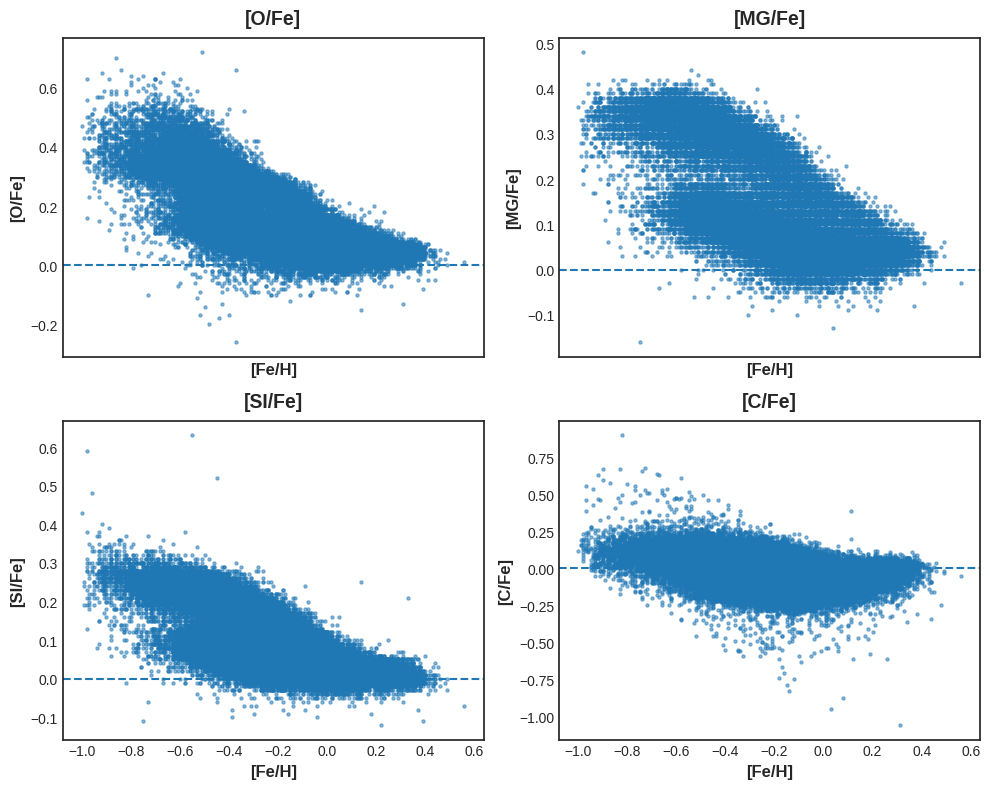

In [135]:
import matplotlib.pyplot as plt

elements = ['o_h', 'mg_h', 'si_h', 'c_h']

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True)

axes = axes.flatten()

for ax, el in zip(axes, elements):
    
    x = apogee['fe_h']
    y = apogee[el] - apogee['fe_h']   # [X/Fe]

    ax.scatter(x, y, s=5, alpha=0.5)

    element_name = el.split('_')[0].upper()
    ax.set_title(f'[{element_name}/Fe]')
    ax.set_xlabel('[Fe/H]')
    ax.set_ylabel(f'[{element_name}/Fe]')
    ax.axhline(0, linestyle='--')

plt.tight_layout()
plt.show()

# Here we focus on getting abundances from Fe and kinematics

In [111]:
columns_for_abundances = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'fe_h', 'o_h', 'mg_h', 'si_h', 'c_h']

apogee = apogee[columns_for_abundances]
harps = harps[columns_for_abundances]

o_features = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'fe_h', 'o_h']
apogee_o = apogee[o_features]
harps_o = harps[o_features]
harps_o.dropna(inplace = True)

si_features = ['U_lsr', 'V_lsr', 'W_lsr', 'P_gal', 'rapo', 'rperi', 'eccentricity', 'zmax', 'fe_h', 'si_h']
apogee_si = apogee[si_features]
harps_si = harps[si_features]
harps_si.dropna(inplace = True)


/tmp/ipykernel_87421/1395065871.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  harps_o.dropna(inplace = True)
/tmp/ipykernel_87421/1395065871.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  harps_si.dropna(inplace = True)


In [76]:
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
    "o_h":          r"$[\mathrm{O/H}]$",
    "mg_h":         r"$[\mathrm{Mg/H}]$",
    "si_h":         r"$[\mathrm{Si/H}]$",
    "c_h":          r"$[\mathrm{C/H}]$",
}

### Spliting data into Trianing and Testing sets

In [138]:
class AbundancePredictor:

    def __init__(self, apogee_df, harps_df, element, features=None, random_state=42):
        """
        Parameters
        ----------
        apogee_df : pandas.DataFrame
            Training dataset (used for train/validation split and tuning).
        harps_df : pandas.DataFrame
            Independent test dataset.
        element : str
            Target abundance (e.g. 'o_h', 'mg_h', 'si_h', 'c_h').
        features : list, optional
            Input features used for prediction.
        """

        self.apogee_df = apogee_df.copy()
        self.harps_df = harps_df.copy()
        self.element = element
        self.random_state = random_state

        if features is None:
            self.features = ['U_lsr', 'V_lsr', 'W_lsr', 
                             'P_gal', 'rapo', 'rperi', 
                             'eccentricity', 'zmax', 'fe_h',
            ]
        else:
            self.features = features

        self.model = None

    def prepare_element_data(self, dropna_harps=True):
        """
        Prepare APOGEE and HARPS dataframes for the selected element.

        Returns
        -------
        apogee_el : DataFrame
            APOGEE dataframe containing features + target element
        harps_el : DataFrame
            HARPS dataframe containing features + target element
        """

        cols = self.features + [self.element]

        self.apogee_el = self.apogee_df[cols].copy()
        self.harps_el  = self.harps_df[cols].copy()

        if dropna_harps:
            self.harps_el = self.harps_el.dropna()

        return self.apogee_el, self.harps_el

    def split_data(self, test_size=0.1):

        X = self.apogee_df[self.features]
        y = self.apogee_df[self.element]

        self.X_train, self.X_val, self.y_train, self.y_val = train_test_split(
            X, y,
            test_size=test_size,
            random_state=self.random_state
        )
        return self.X_train, self.X_val, self.y_train, self.y_val

    def compute_spearman(self, df):
        corr = (
            df.corr(numeric_only=True, method="spearman")[self.element]
            .drop(self.element)
            .sort_values(key=abs, ascending=False)
        )
        return corr
    
    def plot_spearman_correlations(self, pretty_labels, savepath=None):

        corr_apogee = self.compute_spearman(self.apogee_el)
        corr_harps = self.compute_spearman(self.harps_el)

        fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=False)

        datasets = {
            "APOGEE": corr_apogee,
            "HARPS": corr_harps
        }

        axes = axes.flatten()

        for ax, (name, corr) in zip(axes, datasets.items()):

            values = corr.values
            labels = [pretty_labels.get(f, f) for f in corr.index]

            ax.barh(labels, values)
            ax.set_title(name, fontsize=12)
            ax.axvline(0, color="black", linewidth=0.8)
            ax.invert_yaxis()

        fig.supxlabel(f"Spearman correlations with {pretty_labels.get(self.element, self.element)}", fontsize=14)
        fig.supylabel("Features", fontsize=16)

        plt.tight_layout()

        if savepath is not None:
            plt.savefig(savepath, dpi=300)

        plt.show()


    def compute_mi(self, df):
        X = df[self.features]
        y = df[self.element]
        mi = mutual_info_regression(
            X, y,
            random_state=self.random_state
        )
        mi_series = pd.Series(mi, index=X.columns).sort_values(ascending=False)
        return mi_series

    
    def plot_mutual_information(self, pretty_labels, savepath=None):

        mi_apogee = self.compute_mi(self.apogee_el)
        mi_harps  = self.compute_mi(self.harps_el)

        fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=False)

        datasets = {
            "APOGEE": mi_apogee,
            "HARPS": mi_harps
        }

        for ax, (name, mi) in zip(axes, datasets.items()):

            labels = [pretty_labels.get(f, f) for f in mi.index]

            ax.barh(labels, mi.values)
            ax.set_title(name, fontsize=12)
            ax.invert_yaxis()

        fig.supxlabel(
        f"Mutual Information with {pretty_labels.get(self.element, self.element)}",
        fontsize=16
        )
        fig.supylabel("Features", fontsize=16)

        plt.tight_layout()

        if savepath:
            plt.savefig(savepath, dpi=300)

        plt.show()

o_h


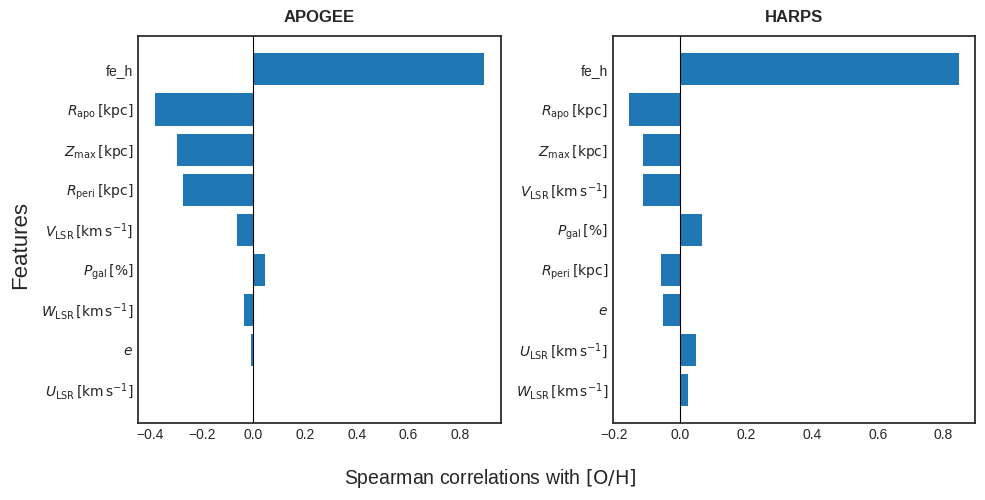

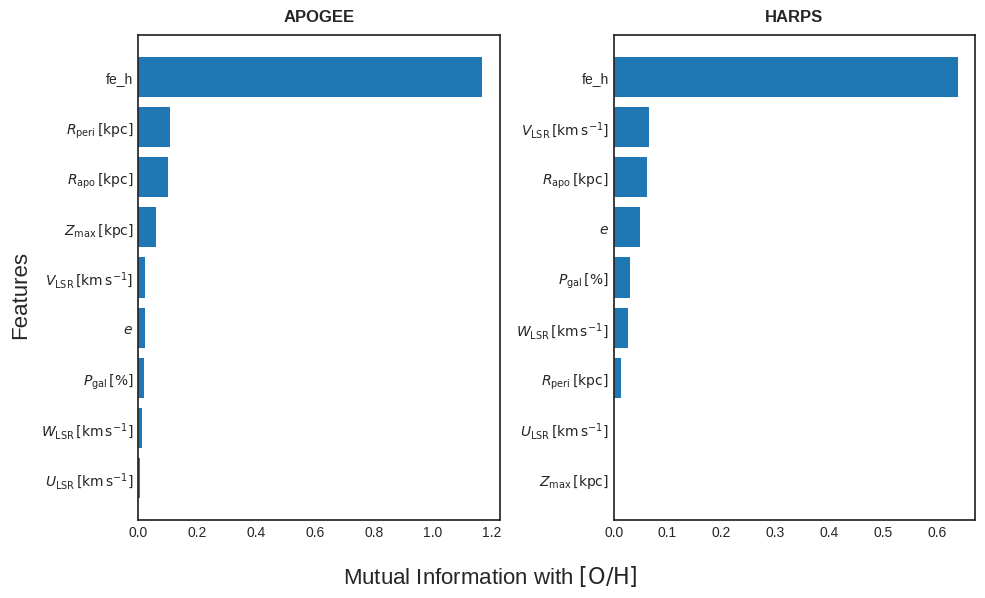

mg_h


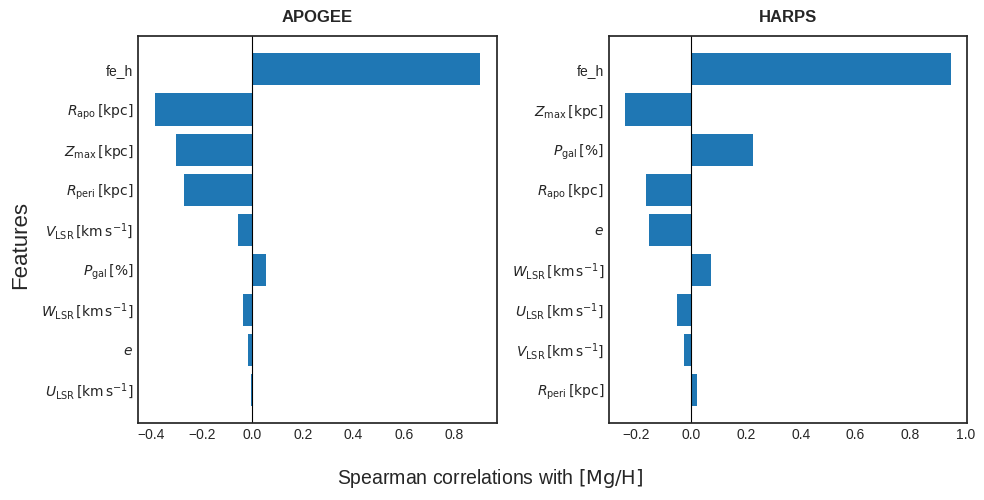

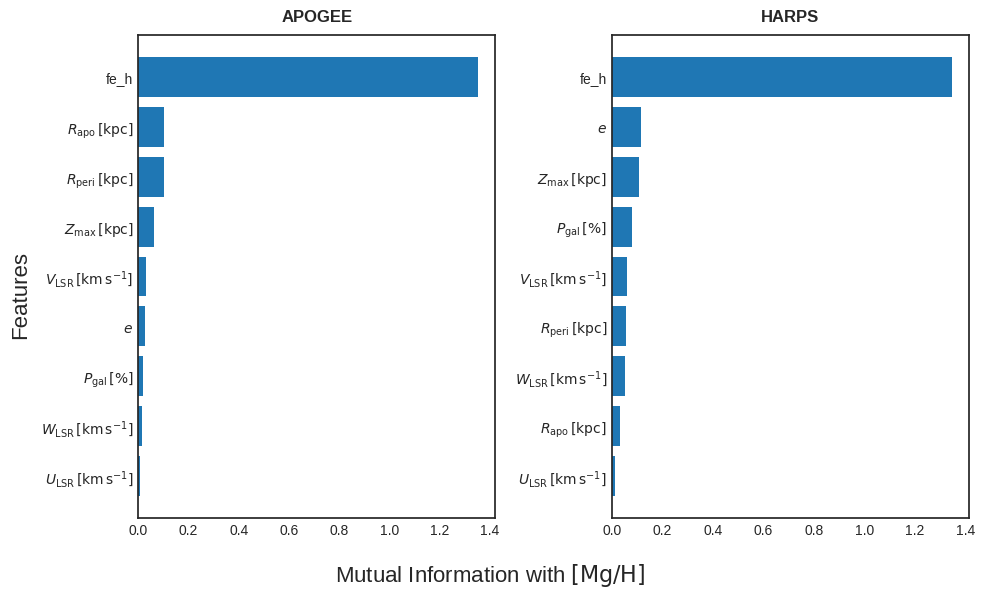

si_h


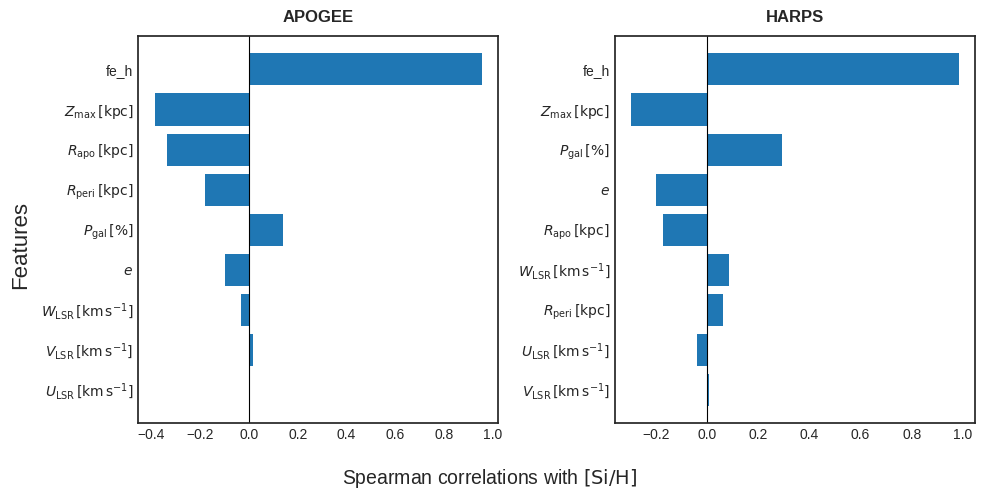

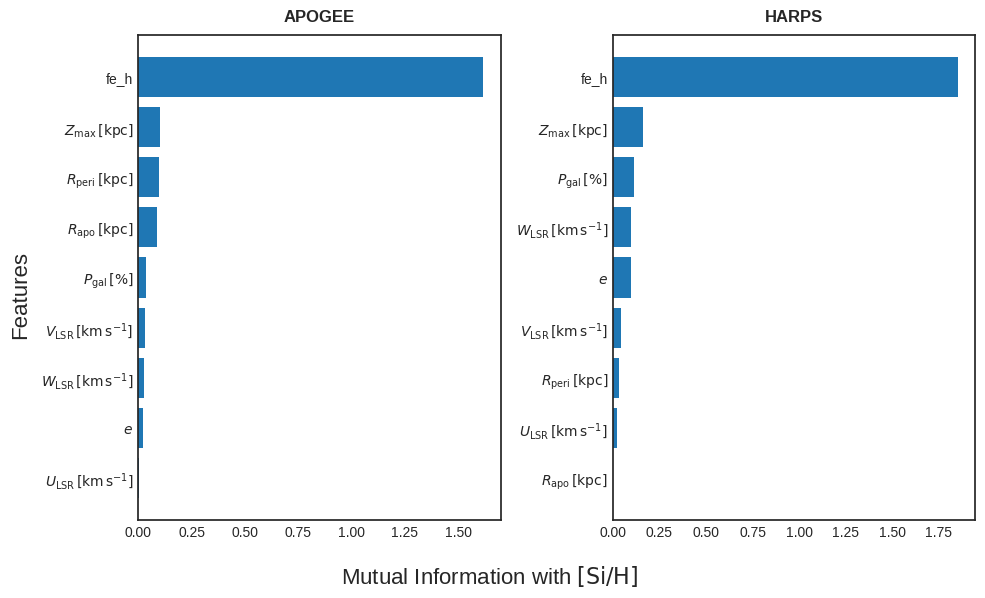

c_h


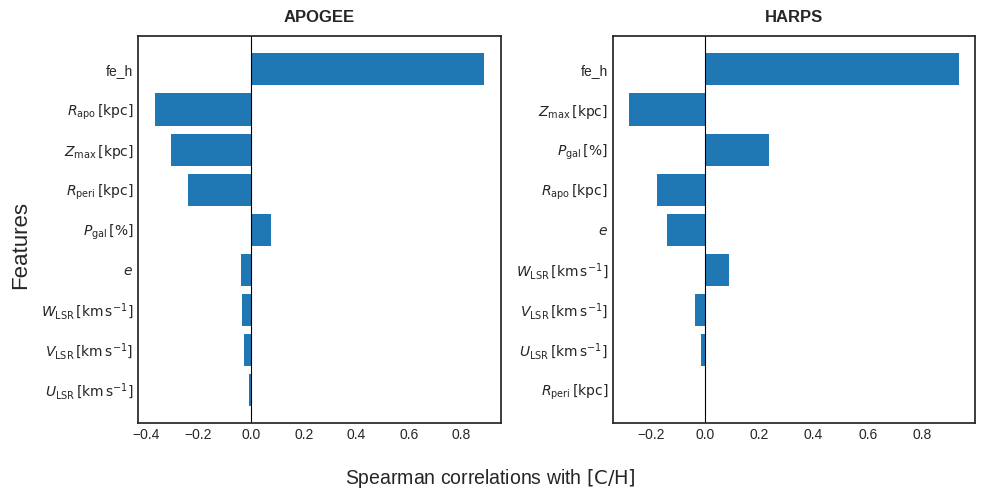

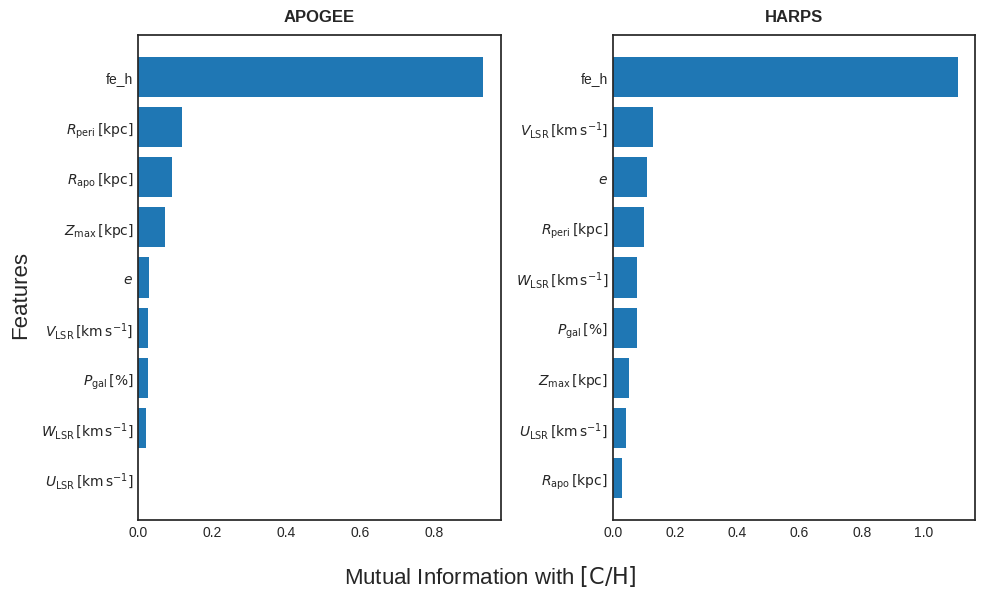

In [139]:
def allinone_predictor(apogee_df, harps_df, element, features, random_state=42):
    predictor = AbundancePredictor(apogee_df, harps_df, element=element, features=features, random_state=random_state)
    apogee_el, harps_el = predictor.prepare_element_data(dropna_harps=True)
    predictor.plot_spearman_correlations(PRETTY_LABELS,
        savepath=f"./figures/correlations_{element}.png"
    )
    predictor.plot_mutual_information(
        PRETTY_LABELS,
        savepath=f"./figures/mi_{element}.png"
    )
    

elements = ['o_h', 'mg_h', 'si_h', 'c_h']
for el in elements:
    print (el)
    allinone_predictor(apogee, harps, element = el, features = None)



In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
import numpy as np
import time

def model_test_CV_models(X, y, models, k=5, random_state=42):
    """
    Perform k-fold cross-validation for multiple models.
    Returns mean and std of RMSE, MAE, and R2.
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()

        rmse_scores = []
        mae_scores = []
        r2_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)

            rmse_scores.append(rmse)
            mae_scores.append(mae)
            r2_scores.append(r2)

        elapsed_time = time.time() - start_time

        results[name] = {
            'mean_rmse': np.mean(rmse_scores),
            'std_rmse': np.std(rmse_scores),
            'mean_mae': np.mean(mae_scores),
            'mean_r2': np.mean(r2_scores),
            'time_sec': elapsed_time
        }

        print(
            f"{name} → "
            f"RMSE: {results[name]['mean_rmse']:.3f} ± {results[name]['std_rmse']:.3f} | "
            f"MAE: {results[name]['mean_mae']:.3f} | "
            f"R²: {results[name]['mean_r2']:.3f} "
            f"({elapsed_time:.2f}s)\n"
        )

    return results